# Specificity of dictionary 276

Specificity is measured on the GPL whitened spectrogram of `/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav`. A local maximum is a column where the motif fits and the dot product is strictly larger than both neighbors. At each local maximum the ratio is the smaller relative drop a shift of `k` columns to either side. `k` is half the motif width. Ratios smaller than the motif's largest ratio divided by `m` (`m` is 2) are removed, and the largest ratio is kept. The number for a motif is the median of what remains.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "analysis" / "evaluation" / "core.py").is_file():
        if str(candidate) not in sys.path:
            sys.path.insert(0, str(candidate))
        break

from analysis.evaluation import evaluate_dictionary
from analysis.evaluation.core import (
    DEFAULT_CATALOG,
    DEFAULT_WAV,
    _dictionary_rows,
    _dot_products,
    _drop_ratio,
    _local_maxima,
    _stitch,
    _whitened_dir,
)

result = evaluate_dictionary()
medians = result["specificity_median"]
distributions = result["specificity"]
shifts = result["k"]
ids = np.array(sorted(medians))
values = np.array([medians[int(i)] for i in ids])
print(result["wav"])
print(
    f"coverage {result['coverage']:.3f}   over-coverage {result['over_coverage']:.2f}   "
    f"m {result['m']}   motifs {len(values)}"
)
print(
    f"median specificity  min {np.nanmin(values):.3f}   "
    f"median {np.nanmedian(values):.3f}   max {np.nanmax(values):.3f}"
)


/home/yfreund/whale_processing/LeiData/SOCAL_H_76_230427_014845.x.wav
coverage 0.544   over-coverage 7.15   m 2.0   motifs 83
median specificity  min 0.348   median 0.621   max 3389.698


## Distribution across motifs

Each bar is the median of one motif's filtered specificity distribution.

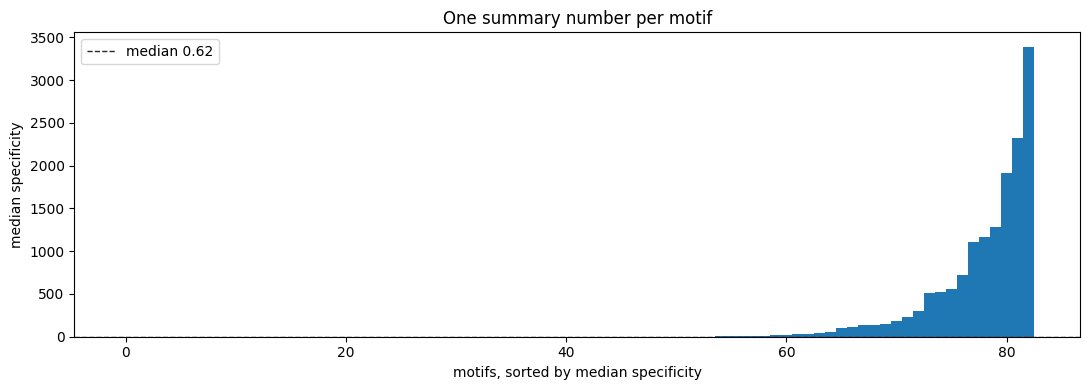

In [2]:
order = np.argsort(values)
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(np.arange(len(order)), values[order], color="C0", width=1.0)
ax.axhline(np.nanmedian(values), color="0.15", ls="--", lw=1, label=f"median {np.nanmedian(values):.2f}")
ax.set_xlabel("motifs, sorted by median specificity")
ax.set_ylabel("median specificity")
ax.set_title("One summary number per motif")
ax.legend()
fig.tight_layout()
plt.show()


## Histogram of motif medians

Each count is one motif. The value is the median of that motif's filtered specificity distribution. The axis is logarithmic because a few medians are orders of magnitude above the rest.

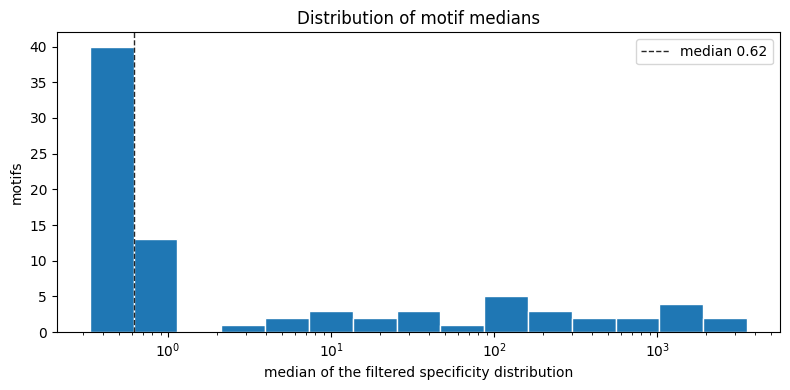

n 83   p25 0.485   median 0.621   p75 27.135


In [3]:
positive = values[np.isfinite(values) & (values > 0)]
bins = np.logspace(np.log10(positive.min() * 0.95), np.log10(positive.max() * 1.05), 16)
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(positive, bins=bins, color="C0", edgecolor="white")
ax.set_xscale("log")
center = float(np.median(positive))
ax.axvline(center, color="0.15", ls="--", lw=1, label=f"median {center:.2f}")
ax.set_xlabel("median of the filtered specificity distribution")
ax.set_ylabel("motifs")
ax.set_title("Distribution of motif medians")
ax.legend()
fig.tight_layout()
plt.show()
print(
    f"n {positive.size}   "
    f"p25 {np.percentile(positive, 25):.3f}   "
    f"median {center:.3f}   "
    f"p75 {np.percentile(positive, 75):.3f}"
)


## Samples for a high, medium, and low motif

High is the largest median below 2. Medium is the motif closest to the median of those summaries. Low is the smallest median. For each motif the histogram is its filtered distribution, and the traces are the three local maxima with the largest dot products. Dashed lines are `k` columns on either side of that local maximum.

high    motif  11  k=16  median=0.739  n=180
medium  motif  60  k=14  median=0.621  n=194
low     motif  13  k=11  median=0.348  n=18


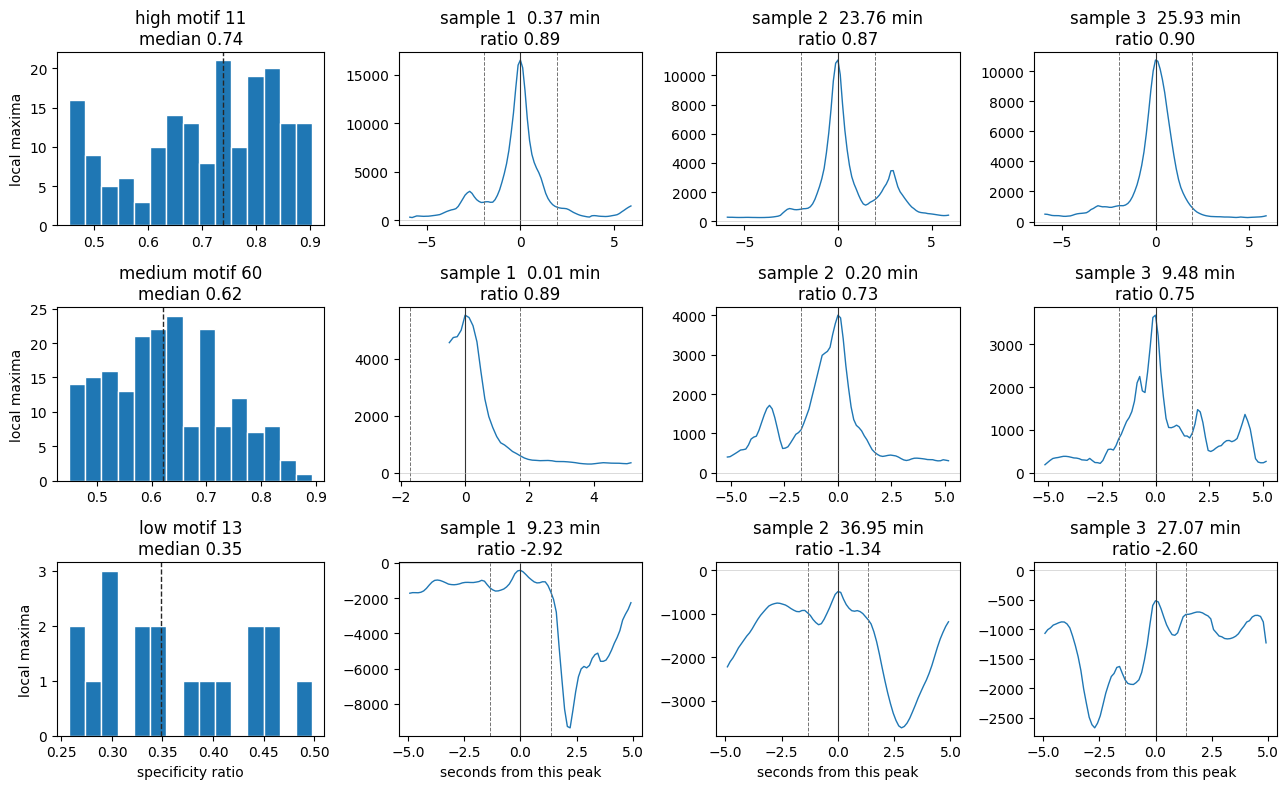

In [4]:
finite = np.isfinite(values)
high_pool = finite & (values > 0.0) & (values < 2.0)
high_id = int(ids[high_pool][np.argmax(values[high_pool])])
medium_id = int(ids[finite][np.argmin(np.abs(values[finite] - np.nanmedian(values)))])
low_id = int(ids[finite][np.argmin(values[finite])])
chosen = [("high", high_id), ("medium", medium_id), ("low", low_id)]
for label, motif_id in chosen:
    print(
        f"{label:6s}  motif {motif_id:3d}  k={shifts[motif_id]:2d}  "
        f"median={medians[motif_id]:.3f}  n={len(distributions[motif_id])}"
    )

spectrogram, _offset = _stitch(_whitened_dir(DEFAULT_CATALOG, DEFAULT_WAV))
rows = {motif_id: (width, path) for motif_id, width, path in _dictionary_rows(DEFAULT_CATALOG, 276)}
sec_per_bin = 24576 / 200000
n_samples = 3

fig, axes = plt.subplots(len(chosen), 1 + n_samples, figsize=(13, 8), gridspec_kw={"width_ratios": [1.1, 1, 1, 1]})
for row, (label, motif_id) in enumerate(chosen):
    width, path = rows[motif_id]
    dots = _dot_products(spectrogram, np.load(path))
    k = int(shifts[motif_id])
    peaks = _local_maxima(dots)
    order = peaks[np.argsort(dots[peaks])[::-1]]
    samples = order[:n_samples]
    ax_hist = axes[row, 0]
    ax_hist.hist(distributions[motif_id], bins=15, color="C0", edgecolor="white")
    ax_hist.axvline(medians[motif_id], color="0.15", ls="--", lw=1)
    ax_hist.set_title(f"{label} motif {motif_id}\nmedian {medians[motif_id]:.2f}")
    ax_hist.set_ylabel("local maxima")
    half = max(3 * k, 40)
    for col, t_star in enumerate(samples):
        ax = axes[row, col + 1]
        lo = max(0, int(t_star) - half)
        hi = min(dots.size, int(t_star) + half + 1)
        lag_s = (np.arange(lo, hi) - int(t_star)) * sec_per_bin
        ax.plot(lag_s, dots[lo:hi], color="C0", lw=1)
        ax.axvline(0.0, color="0.2", lw=0.8)
        for step in (-k, k):
            ax.axvline(step * sec_per_bin, color="0.45", lw=0.7, ls="--")
        ax.axhline(0.0, color="0.75", lw=0.4)
        minute = int(t_star) * sec_per_bin / 60.0
        ratio = _drop_ratio(dots, int(t_star), k)
        ax.set_title(f"sample {col + 1}  {minute:.2f} min\nratio {ratio:.2f}")
axes[-1, 0].set_xlabel("specificity ratio")
for col in range(1, n_samples + 1):
    axes[-1, col].set_xlabel("seconds from this peak")
fig.tight_layout()
plt.show()


## Motifs with median specificity above 10

Each image is the cube root of the absolute motif, from 12 Hz to 1500 Hz, which is where these motifs are concentrated. The jet scale on each panel runs from that panel's 2nd percentile to its 98th, so the colormap covers the motif instead of a few extreme pixels.

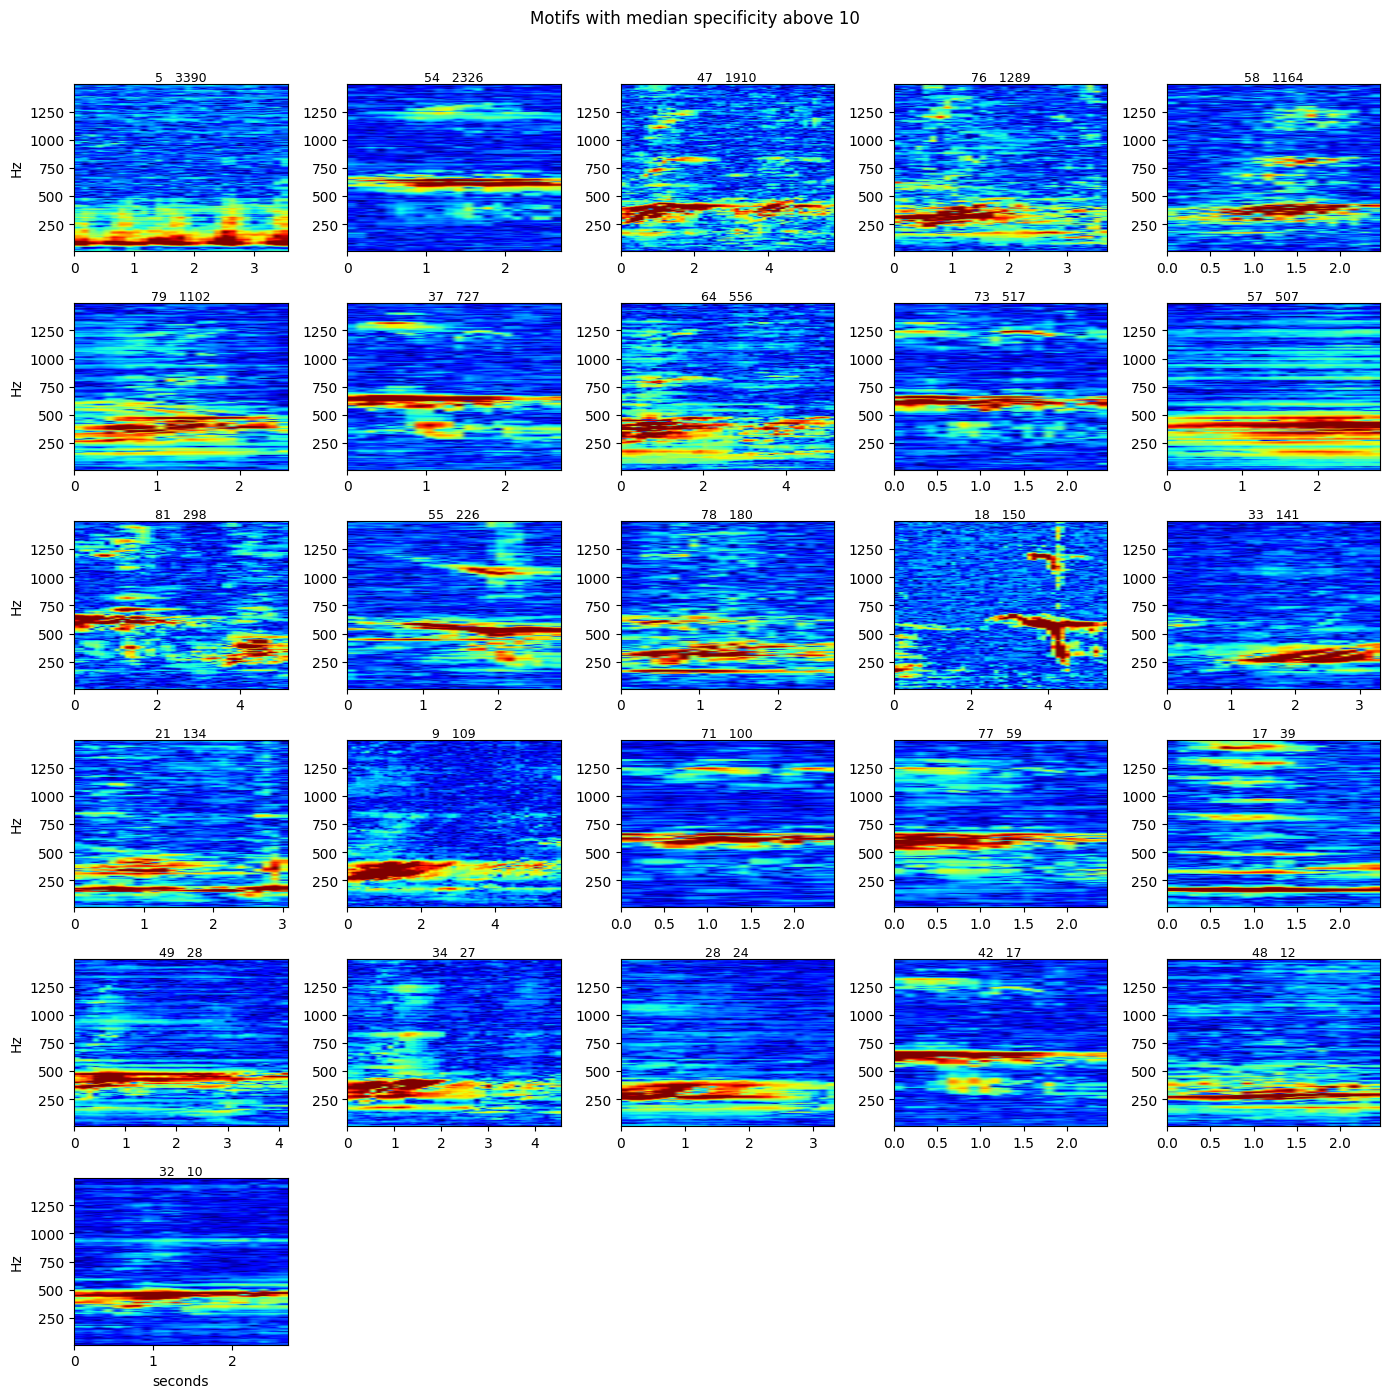

26 motifs, 12–1495 Hz


In [5]:
from analysis.GPL_Python.gpl_outputs import display_from_spwhiten
from analysis.dict_learning.code.io import discover_windows

selected = ids[np.isfinite(values) & (values > 10.0)]
selected = selected[np.argsort(values[np.isin(ids, selected)])[::-1]]
window0 = discover_windows(_whitened_dir(DEFAULT_CATALOG, DEFAULT_WAV))[0]
freq_axis = np.linspace(0.0, float(window0.sample_freq) / 2.0, int(window0.fftl) // 2)
i0 = int(np.argmin(np.abs(freq_axis - float(window0.start_freq))))
freqs = freq_axis[i0 : i0 + 1637]
band = np.flatnonzero(freqs <= 1500.0)
band_lo = int(band[0])
band_hi = int(band[-1]) + 1
f_lo = float(freqs[band_lo])
f_hi = float(freqs[band_hi - 1])
rows = {motif_id: path for motif_id, _width, path in _dictionary_rows(DEFAULT_CATALOG, 276)}
sec_per_bin = 24576 / 200000

ncols = 5
nrows = int(np.ceil(len(selected) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.3 * nrows))
axes = np.atleast_2d(axes)
for panel, motif_id in enumerate(selected):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    atom = np.load(rows[int(motif_id)])
    shown = display_from_spwhiten(atom)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    if not np.isfinite(lo) or hi <= lo:
        lo, hi = float(np.min(shown)), float(np.max(shown))
    extent = [0.0, atom.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(f"{int(motif_id)}   {medians[int(motif_id)]:.0f}", fontsize=9, pad=2)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(selected), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle("Motifs with median specificity above 10", y=1.01)
fig.tight_layout()
plt.show()
print(f"{len(selected)} motifs, {f_lo:.0f}–{f_hi:.0f} Hz")


## Motifs with median specificity above 100

These are the motifs from the figure above whose median is above 100, drawn the same way: cube root of the absolute motif, 12 Hz to 1500 Hz, jet scaled to each panel's 2nd and 98th percentile.

18 of the 26 motifs above 10


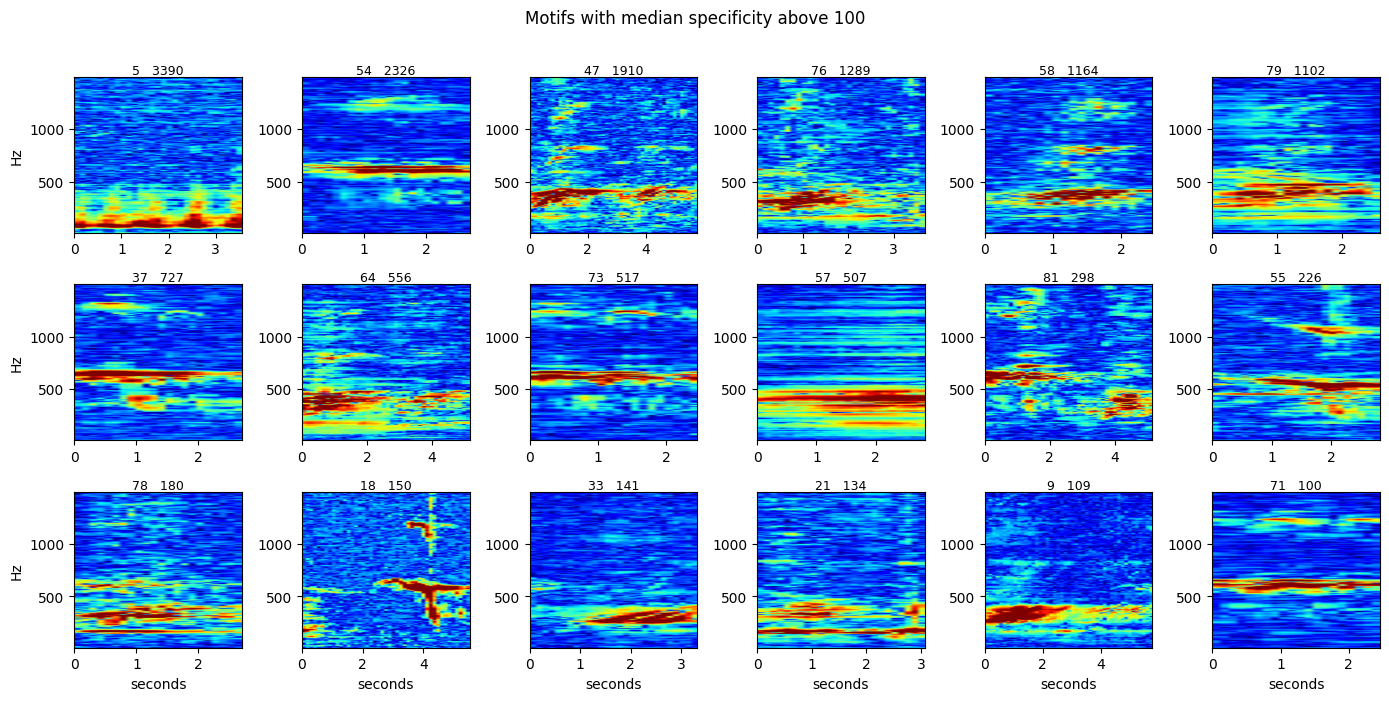

In [6]:
hot = [int(motif_id) for motif_id in selected if medians[int(motif_id)] > 100]
print(f"{len(hot)} of the {len(selected)} motifs above 10")

ncols = 6
nrows = int(np.ceil(len(hot) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.3 * nrows))
axes = np.atleast_2d(axes)
for panel, motif_id in enumerate(hot):
    r, c = divmod(panel, ncols)
    ax = axes[r, c]
    atom = np.load(rows[motif_id])
    shown = display_from_spwhiten(atom)[band_lo:band_hi]
    lo, hi = np.percentile(shown, [2, 98])
    if not np.isfinite(lo) or hi <= lo:
        lo, hi = float(np.min(shown)), float(np.max(shown))
    extent = [0.0, atom.shape[1] * sec_per_bin, f_lo, f_hi]
    ax.imshow(shown, origin="lower", aspect="auto", cmap="jet", vmin=lo, vmax=hi, extent=extent)
    ax.set_title(f"{motif_id}   {medians[motif_id]:.0f}", fontsize=9, pad=2)
    if c == 0:
        ax.set_ylabel("Hz")
    if r == nrows - 1:
        ax.set_xlabel("seconds")
for panel in range(len(hot), nrows * ncols):
    r, c = divmod(panel, ncols)
    axes[r, c].axis("off")
fig.suptitle("Motifs with median specificity above 100", y=1.01)
fig.tight_layout()
plt.show()
